# Dark-energy law lab

A workbench for one idea: **dark energy that depends on how empty space is.**

The law you're testing:

* empty space carries the most dark energy (the **cap**),
* the more matter a region holds, the less it carries (the **inverse** part),
* above a density limit it **stops** altogether, so galaxies and clusters carry none,
* and empty space **compounds**: its volume grows as $dV/dt \propto V^p$, with $p = 1$ meaning in proportion to volume.

Every law you write down here is scored against real data:

| Test | Data | What it checks |
|---|---|---|
| Expansion history | 1,657 Pantheon+ supernovae (full covariance, SH0ES Cepheid anchors) and 13 DESI DR2 BAO distances | How dark energy's total strength changed over the last ~11 billion years |
| Galaxy motions | 450 Pantheon+ host galaxies against the 2M++ gravity map | Whether lumpy dark energy makes matter flow out of voids faster than gravity alone |
| Galaxies | 175 SPARC rotation curves | That the law leaves galaxies alone |
| Voids | Typical 10, 30 and 100 Mpc voids | What the law predicts for void expansion |
| Microwave background | Planck 2018 distance priors ($R$, $\ell_A$, $\omega_b$) | The distance to $z \approx 1090$ and the matter density (sections 12–15) |

**How to use it.** Run everything top to bottom once (a few minutes, mostly section 14; the first run downloads ~35 MB into `data/`). Then edit the law in **section 2**, write your own density law in **section 10**, or write any dark-energy history in **section 15**, and re-run from there. Section 9 searches the density laws; section 14 compares surface-growth laws with and without the CMB.

Requirements: Python 3.10+, `numpy`, `scipy`, `pandas`, `matplotlib`.

In [1]:
# 0. Setup
import hashlib, math, shutil, time, urllib.request, zipfile
from dataclasses import dataclass, replace
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import integrate, optimize, special

DATA = Path("data")             # downloaded data (cached; delete to re-download)
OUT = Path("lab_outputs")       # figures and tables written by this notebook
DATA.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

C_KMS = 299792.458              # speed of light, km/s
G_SI = 6.67430e-11              # m^3 kg^-1 s^-2
MPC_M, KPC_M = 3.0856776e22, 3.0856776e19
M_P = 1.67262192e-27            # proton mass, kg
LN10_5 = math.log(10) / 5
rng = np.random.default_rng(2026)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e4e7eb", "grid.linewidth": 0.8, "axes.edgecolor": "#a3abb5",
    "axes.labelcolor": "#2a313a", "xtick.color": "#5b6470", "ytick.color": "#5b6470",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
    "lines.linewidth": 2.0,
})
COL = dict(law="#eb6834", uniform="#2a78d6", alt="#1baf7a", data="#1f2933", muted="#8a94a3")
LAW_COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#e34948"]   # uniform first, then your laws
print("ready")

ready


## 1. Data

Four public files plus SPARC. Each download is cached in `data/` and checked against a fingerprint (SHA-256) of the copy this notebook was built with. A "differs" message means the provider updated the file, not necessarily that anything is wrong.

* **Pantheon+SH0ES** distances and covariance — Scolnic et al. (2022), Brout et al. (2022), from the team's GitHub release.
* **DESI DR2 BAO** — the Gaussian summary of the DR2 measurements (DESI 2025), via the Cobaya `bao_data` repository.
* **SPARC** rotation curves — Lelli, McGaugh & Schombert (2016). Optional; only the galaxy check needs it. The reference fingerprint is the one your own galaxy run recorded for `Rotmod_LTG.zip`.

In [2]:
RAW_PP = "https://raw.githubusercontent.com/PantheonPlusSH0ES/DataRelease/main/Pantheon%2B_Data/4_DISTANCES_AND_COVAR/"
RAW_BAO = "https://raw.githubusercontent.com/CobayaSampler/bao_data/master/desi_bao_dr2/"
SOURCES = {
    "pantheon": dict(path=DATA / "pantheon" / "Pantheon+SH0ES.dat", urls=[RAW_PP + "Pantheon%2BSH0ES.dat"],
                     sha256="1cb0fc379ef066afdc2ffd1857681cc478024570d8a3eba284fb645775198cf8"),
    "pantheon_cov": dict(path=DATA / "pantheon" / "Pantheon+SH0ES_STAT+SYS.cov", urls=[RAW_PP + "Pantheon%2BSH0ES_STAT%2BSYS.cov"],
                         sha256="abf806d966485e64afdb359c87bffc0ecc00d05eff0a31ced66f247385df0fdc"),
    "desi_mean": dict(path=DATA / "desi" / "desi_gaussian_bao_ALL_GCcomb_mean.txt", urls=[RAW_BAO + "desi_gaussian_bao_ALL_GCcomb_mean.txt"],
                      sha256="9ac154ab583ce759c0f7eef3c978c7c70a6ead2d18774caceadf1a350a640585"),
    "desi_cov": dict(path=DATA / "desi" / "desi_gaussian_bao_ALL_GCcomb_cov.txt", urls=[RAW_BAO + "desi_gaussian_bao_ALL_GCcomb_cov.txt"],
                     sha256="252a143274c8a07c78694c119617d36594f6d7965d00319ca611c6ffb886e509"),
    "sparc_zip": dict(path=DATA / "sparc" / "Rotmod_LTG.zip",
                      urls=["https://astroweb.case.edu/SPARC/Rotmod_LTG.zip",
                            "https://zenodo.org/records/16284118/files/Rotmod_LTG.zip?download=1"],
                      sha256="0a80cc90714828cc28b7dd57923576714d209f2490328c087c4a4ad607faf588"),
}

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def fetch(key, required=True):
    """Download one file into data/ unless it is already there, then compare its fingerprint."""
    src = SOURCES[key]; path = src["path"]
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.exists():
        for url in src["urls"]:
            try:
                print(f"downloading {path.name} from {url.split('/')[2]} ...")
                req = urllib.request.Request(url, headers={"User-Agent": "dark-energy-law-lab"})
                with urllib.request.urlopen(req, timeout=300) as r, open(path, "wb") as fh:
                    shutil.copyfileobj(r, fh)
                break
            except Exception as err:
                print(f"  failed: {err}")
                if path.exists():
                    path.unlink()
        else:
            msg = f"Could not download {path.name}. Save it by hand as {path} and re-run this cell."
            if required:
                raise RuntimeError(msg)
            print(msg)
            return None
    same = sha256(path) == src["sha256"]
    print(f"  {path.name}: {'fingerprint matches' if same else 'present, fingerprint differs from the reference copy'}")
    return path

def get_sparc():
    folder = DATA / "sparc" / "Rotmod_LTG"
    files = list(folder.glob("*_rotmod.dat")) if folder.exists() else []
    if len(files) >= 170:
        print(f"  SPARC: {len(files)} rotation curves already in {folder}")
        return folder
    z = fetch("sparc_zip", required=False)
    if z is None:
        return None
    folder.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(z) as zz:
        for member in zz.namelist():
            if member.endswith("_rotmod.dat"):
                (folder / Path(member).name).write_bytes(zz.read(member))   # flat names only
    print(f"  SPARC: unpacked {len(list(folder.glob('*_rotmod.dat')))} rotation curves")
    return folder

pp = pd.read_csv(fetch("pantheon"), sep=r"\s+")
_cov = pd.read_csv(fetch("pantheon_cov"), header=None).to_numpy().ravel()
PP_COV = _cov[1:].reshape(int(_cov[0]), int(_cov[0]))
_rows = [ln.split() for ln in open(fetch("desi_mean")) if ln.strip() and not ln.startswith("#")]
BAO_TABLE = pd.DataFrame(dict(z=[float(r[0]) for r in _rows], value=[float(r[1]) for r in _rows], kind=[r[2] for r in _rows]))
BAO_COV = np.loadtxt(fetch("desi_cov"))
SPARC_DIR = get_sparc()
print(f"\n{len(pp)} supernova light curves ({pp.CID.nunique()} supernovae), {len(BAO_TABLE)} DESI BAO measurements")

  Pantheon+SH0ES.dat: fingerprint matches
  Pantheon+SH0ES_STAT+SYS.cov: fingerprint matches


  desi_gaussian_bao_ALL_GCcomb_mean.txt: fingerprint matches
  desi_gaussian_bao_ALL_GCcomb_cov.txt: fingerprint matches
  SPARC: 175 rotation curves already in data/sparc/Rotmod_LTG

1701 supernova light curves (1543 supernovae), 13 DESI BAO measurements


## 2. Your law

A patch of space with matter density $x$ carries dark-energy density

$$\rho_{\rm DE}(x, t) = \rho_{\rm cap}(t)\; S(x), \qquad S(x) = \frac{1}{1 + (x/x_{1/2})^{\,n}} \times \text{cutoff}(x).$$

* $x$ is density in units of **today's** average cosmic matter density. Today an average patch has $x = 1$, a deep void $0.1$–$0.3$, walls and filaments $3$–$30$, galaxy clusters $200$–$1000$, a galaxy's disc about $10^6$.
* $S(0) = 1$ is the **cap**: perfectly empty space carries the most.
* `x_half` is the density where dark energy has fallen to half of the cap, and `n` sets how sharply it falls (1 = plain inverse).
* `x_cut` is where it **stops**; `cut_width_dex` softens the switch (0 = hard step).
* `p` is your compounding exponent. If empty space grows as $dV/dt \propto V^p$, the cap evolves as $\rho_{\rm cap} \propto a^{-6(1-p)}$, which for $p = 1$ is constant (a cosmological constant).

**The density is physical.** In the past the whole universe was denser, $x_{\rm mean} = (1+z)^3$: eight times today's value at $z = 1$ and 27 times at $z = 2$. Your law therefore also decides when dark energy switched on. That turns out to be the strongest constraint on it.

Edit `MY_LAW` below and re-run from here.

In [3]:
@dataclass
class DarkEnergyLaw:
    name: str = "capped inverse law"
    x_half: float = 30.0         # density where dark energy has fallen to half its cap
    n: float = 1.0               # sharpness: 1 = plain inverse, larger = sharper switch-off
    x_cut: float = 200.0         # above this density dark energy stops altogether
    cut_width_dex: float = 0.15  # softness of the cutoff, in decades of density (0 = hard step)
    p: float = 1.0               # compounding: empty space grows as dV/dt ∝ V^p

    def shape(self, x):
        """Fraction of the cap carried by a patch of density x (x in units of today's mean)."""
        x = np.maximum(np.asarray(x, dtype=float), 0.0)
        with np.errstate(over="ignore", divide="ignore", invalid="ignore"):
            s = 1.0 / (1.0 + (x / self.x_half) ** self.n)      # x_half = inf -> 1 everywhere
        if np.isfinite(self.x_cut):
            if self.cut_width_dex <= 0:
                s = np.where(x < self.x_cut, s, 0.0)
            else:
                t = np.log10(np.maximum(x, 1e-300) / self.x_cut) / self.cut_width_dex
                s = s * 0.5 * special.erfc(t / math.sqrt(2.0))
        return s

UNIFORM = DarkEnergyLaw(name="uniform (standard model)", x_half=math.inf, x_cut=math.inf)

# ---- edit this -------------------------------------------------------------------------
MY_LAW = DarkEnergyLaw(name="my law", x_half=30.0, n=1.0, x_cut=200.0, cut_width_dex=0.15, p=1.0)
# -----------------------------------------------------------------------------------------

REGIONS = {"empty space (the cap)": 0.0, "deep void": 0.2, "average patch": 1.0, "wall": 3.0,
           "filament": 10.0, "cluster": 500.0, "galaxy disc": 1e6}
pd.DataFrame({"density x": REGIONS.values(),
              "dark energy, % of the cap": np.round(100 * MY_LAW.shape(list(REGIONS.values())), 2)},
             index=REGIONS.keys())

,density x,"dark energy, % of the cap"
empty space (the cap),0.0,100.00
deep void,0.2,99.34
average patch,1.0,96.77
wall,3.0,90.91
filament,10.0,75.00
cluster,500.0,0.02
galaxy disc,1000000.0,0.00


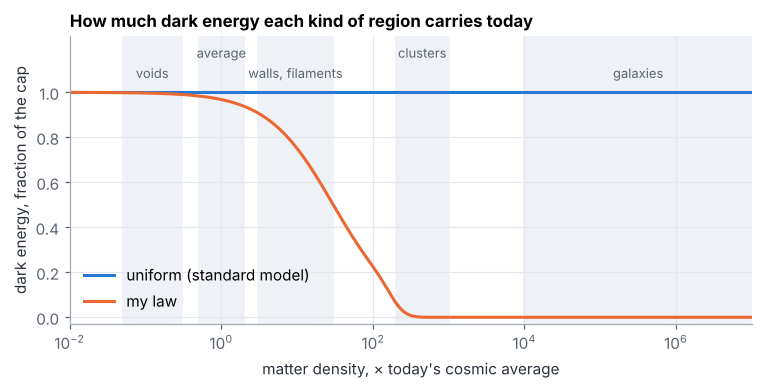

In [4]:
REGION_BANDS = [("voids", 0.05, 0.3), ("average", 0.5, 2), ("walls, filaments", 3, 30),
                ("clusters", 200, 1000), ("galaxies", 1e4, 1e7)]

def plot_shapes(laws, ax=None):
    ax = ax or plt.subplots(figsize=(8, 3.4))[1]
    x = np.geomspace(1e-2, 1e7, 600)
    for i, (name, lo, hi) in enumerate(REGION_BANDS):
        ax.axvspan(lo, hi, color="#eef1f5", zorder=0)
        ax.text(math.sqrt(lo * hi), 1.05 + 0.09 * (i % 2), name, ha="center", va="bottom", fontsize=8.5, color="#5b6470")
    for law, c in zip(laws, LAW_COLOURS):
        ax.plot(x, law.shape(x), color=c, label=law.name)
    ax.set_xscale("log"); ax.set_ylim(-0.03, 1.25); ax.set_xlim(x[0], x[-1])
    ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
    ax.set_xlabel("matter density, × today's cosmic average"); ax.set_ylabel("dark energy, fraction of the cap")
    ax.legend(loc="lower left")
    return ax

plot_shapes([UNIFORM, MY_LAW]); plt.title("How much dark energy each kind of region carries today", loc="left"); plt.show()

## 3. How the universe's volume is shared out

The mean dark energy is a **volume average** of your law over the cosmic web, so we need to know how much of the universe's volume sits at each density, then and now.

Matter is smoothed in cells of radius `R_mpc` (default 2 Mpc). The cell densities follow a lognormal distribution whose width comes from standard linear growth (BBKS spectrum, σ₈ = 0.81; Coles & Jones 1991). Today about 39% of the volume is below 0.3× the mean, and less than 0.1% is above 30×. A smaller `R_mpc` gives a lumpier web; try 1–4 Mpc to see how much your conclusions depend on it.

From this we get two numbers at each redshift:

* $\langle S\rangle(z)$, the mean dark energy relative to the cap, which sets the expansion history,
* $\kappa(z) = -\langle x\,S'(x)\rangle / \langle S\rangle$, how strongly large-scale dark energy follows large-scale matter, which feeds the growth of structure (section 5).

rms density contrast in 2 Mpc cells today: 2.10
  share of today's volume below 0.3x (deep voids)   38.70%
  share of today's volume 0.3x to 3x                53.76%
  share of today's volume 3x to 30x                  7.46%
  share of today's volume above 30x                  0.08%


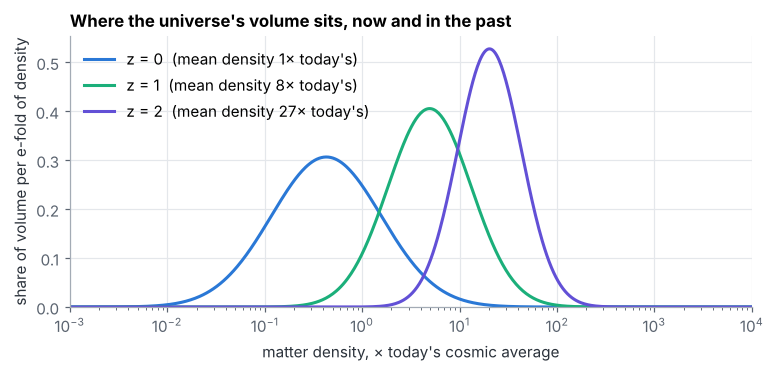

In [5]:
def _tophat(y):
    y = np.asarray(y, float); out = np.empty_like(y); small = y < 1e-2
    out[small] = 1 - y[small] ** 2 / 10
    ys = y[~small]; out[~small] = 3 * (np.sin(ys) - ys * np.cos(ys)) / ys ** 3
    return out

def sigma_tophat(R_mpc, sigma8=0.81, Om=0.315, h=0.674, ns=0.965, Ob=0.049):
    """Linear rms density contrast in spheres of radius R (BBKS transfer function)."""
    gamma = Om * h * math.exp(-Ob * (1 + math.sqrt(2 * h) / Om))
    k = np.logspace(-4, 3, 8000); q = k / gamma                           # k in h/Mpc
    T = np.log(1 + 2.34 * q) / (2.34 * q) * (1 + 3.89 * q + (16.1 * q) ** 2 + (5.46 * q) ** 3 + (6.71 * q) ** 4) ** -0.25
    P = k ** ns * T ** 2
    var = lambda Rh: integrate.trapezoid(k ** 2 * P * _tophat(k * Rh) ** 2, k) / (2 * math.pi ** 2)
    return sigma8 * math.sqrt(var(R_mpc * h) / var(8.0))

def growth_lcdm(z, Om=0.315):
    """Standard-model linear growth factor with D(z=0) = 1."""
    E = lambda a: math.sqrt(Om * a ** -3 + 1 - Om)
    D = lambda a: 2.5 * Om * E(a) * integrate.quad(lambda aa: 1 / (aa * E(aa)) ** 3, 0, a, limit=200)[0]
    return np.array([D(1 / (1 + zi)) for zi in np.atleast_1d(z)]) / D(1.0)

class CosmicWeb:
    def __init__(self, R_mpc=2.0, sigma8=0.81, nodes=120):
        self.R_mpc = R_mpc
        self.z = np.concatenate([np.linspace(0, 3, 151), np.geomspace(3, 1100, 80)[1:]])
        self.sigma = sigma_tophat(R_mpc, sigma8) * growth_lcdm(self.z)
        s2 = np.log1p(self.sigma ** 2); mu, s = -0.5 * s2, np.sqrt(s2)
        self.mu, self.s = mu, s                                               # ln(density / mean at that time) ~ Normal(mu, s)
        t, w = np.polynomial.hermite.hermgauss(nodes)
        self.wts = w / math.sqrt(math.pi)                                     # Gauss-Hermite volume weights
        self.x = (1 + self.z)[:, None] ** 3 * np.exp(mu[:, None] + math.sqrt(2.0) * s[:, None] * t[None, :])

    def averages(self, law):
        """<S>(z) and -<x dS/dx>(z), volume-averaged over the web."""
        S = law.shape(self.x); h = 1e-3
        xdS = (law.shape(self.x * math.exp(h)) - law.shape(self.x * math.exp(-h))) / (2 * h)
        return S @ self.wts, -(xdS @ self.wts)

    def volume_fraction(self, lo, hi, z=0.0):
        i = int(np.argmin(np.abs(self.z - z)))
        return float(self.wts[(self.x[i] >= lo) & (self.x[i] < hi)].sum())

WEB = CosmicWeb(R_mpc=2.0)
print(f"rms density contrast in 2 Mpc cells today: {WEB.sigma[0]:.2f}")
for lo, hi, label in [(0, 0.3, "below 0.3x (deep voids)"), (0.3, 3, "0.3x to 3x"), (3, 30, "3x to 30x"), (30, np.inf, "above 30x")]:
    print(f"  share of today's volume {label:24s} {100 * WEB.volume_fraction(lo, hi):6.2f}%")

fig, ax = plt.subplots(figsize=(8, 3.2))
xs = np.geomspace(1e-3, 1e4, 600)
for zz, c in [(0, COL["uniform"]), (1, COL["alt"]), (2, "#6250d6")]:
    i = int(np.argmin(np.abs(WEB.z - zz)))
    y = np.log(xs / (1 + WEB.z[i]) ** 3)                                     # ln(density / mean at that time)
    pdf = np.exp(-0.5 * ((y - WEB.mu[i]) / WEB.s[i]) ** 2) / (WEB.s[i] * math.sqrt(2 * math.pi))
    ax.plot(xs, pdf, color=c, label=f"z = {zz}  (mean density {(1 + zz) ** 3:.0f}× today's)")
ax.set_xscale("log"); ax.set_xlim(1e-3, 1e4); ax.set_ylim(0)
ax.set_xlabel("matter density, × today's cosmic average"); ax.set_ylabel("share of volume per e-fold of density")
ax.set_title("Where the universe's volume sits, now and in the past", loc="left"); ax.legend(); plt.show()

## 4. Expansion history: supernovae and BAO

For a law and a matter density $\Omega_m$ the expansion rate is

$$H^2(z) = H_0^2\left[\Omega_m(1+z)^3 + (1-\Omega_m)\,\frac{\bar\rho_{\rm DE}(z)}{\bar\rho_{\rm DE}(0)}\right], \qquad \bar\rho_{\rm DE}(z) = \rho_{\rm cap}(z)\,\langle S\rangle(z).$$

* **Supernovae** use the official Pantheon+SH0ES recipe: Cepheid distances for the 77 calibrator hosts, the cosmology for supernovae above $z = 0.01$, and the full covariance. The supernova absolute magnitude and $H_0$ enter linearly, so they are solved for exactly at every step.
* **BAO** distances are ratios to the sound horizon $r_d$. Their overall scale $c/(H_0 r_d)$ is also solved exactly, so BAO tests only the *shape* of the expansion history and does not care about the Hubble tension.

Scores are $\chi^2$ differences from uniform dark energy, with $\Omega_m$ re-fitted for every law: 4 is about 2σ worse, 25 about 5σ.

In [6]:
Z_GRID = np.concatenate([np.linspace(0, 0.2, 801), np.linspace(0.2, 2.6, 2401)[1:]])

class LawModel:
    """Everything about a law that does not depend on Om."""
    def __init__(self, law, web=None):
        web = web or WEB
        self.law = law
        mean_S, resp = web.averages(law)
        if not mean_S[0] > 0:
            raise ValueError("this law leaves no dark energy anywhere today; raise x_half or x_cut")
        self.mean_S0 = float(mean_S[0])
        cap = (1 + web.z) ** (6 * (1 - law.p))                 # evolution of the cap itself
        self.web_z = web.z
        self.f_web = cap * mean_S / self.mean_S0              # mean dark energy relative to today
        self.g_web = cap * resp / self.mean_S0                # kappa(z) * f(z): the term that feeds growth
        with np.errstate(invalid="ignore", divide="ignore"):
            self.kappa_web = np.where(mean_S > 1e-12, resp / mean_S, 0.0)
        self._lz = np.log1p(web.z)
        self.f_grid = self.f(Z_GRID)

    def f(self, z): return np.interp(np.log1p(z), self._lz, self.f_web)
    def g(self, z): return np.interp(np.log1p(z), self._lz, self.g_web)
    def kappa(self, z): return np.interp(np.log1p(z), self._lz, self.kappa_web)

    def w_eff(self, z):
        """Equation of state a smooth fluid would need to mimic this mean dark energy."""
        dlnf = np.gradient(np.log(np.maximum(self.f_web, 1e-300)), self._lz)
        return -1 + np.interp(np.log1p(z), self._lz, dlnf) / 3

def background(lm, Om):
    E = np.sqrt(Om * (1 + Z_GRID) ** 3 + (1 - Om) * lm.f_grid)
    return E, integrate.cumulative_trapezoid(1 / E, Z_GRID, initial=0.0)   # comoving distance in units of c/H0

class Supernovae:
    def __init__(self, table, cov):
        use = ((table.IS_CALIBRATOR == 1) | (table.zHD > 0.01)).to_numpy()
        self.idx = np.where(use)[0]; d = table.iloc[self.idx]
        self.zhd, self.zhel = d.zHD.to_numpy(), d.zHEL.to_numpy()
        self.mb, self.ceph = d.m_b_corr.to_numpy(), d.CEPH_DIST.to_numpy()
        self.cal = (d.IS_CALIBRATOR == 1).to_numpy()
        self.W = np.linalg.inv(cov[np.ix_(self.idx, self.idx)])
        self.A = np.column_stack([np.ones(len(self.idx)), np.where(self.cal, 0.0, -1.0)])   # columns: M, 5 log10 h
        self.Finv = np.linalg.inv(self.A.T @ self.W @ self.A)
        self.n = len(self.idx)

    def chi2(self, lm, Om, details=False):
        _, Dc = background(lm, Om)
        mu100 = 5 * np.log10((1 + self.zhel) * (C_KMS / 100) * np.interp(self.zhd, Z_GRID, Dc)) + 25
        y = self.mb - np.where(self.cal, self.ceph, mu100)
        Wy = self.W @ y; b = self.A.T @ Wy; theta = self.Finv @ b
        chi2 = float(y @ Wy - b @ theta)
        return (chi2, dict(M=float(theta[0]), H0=float(100 * 10 ** (theta[1] / 5)))) if details else chi2

class BAOData:
    def __init__(self, table, cov):
        self.z, self.d, self.kind = table.z.to_numpy(), table.value.to_numpy(), table.kind.to_numpy()
        self.W = np.linalg.inv(cov); self.err = np.sqrt(np.diag(cov))

    def u(self, lm, Om):
        E, Dc = background(lm, Om)
        dm = np.interp(self.z, Z_GRID, Dc); dh = 1 / np.interp(self.z, Z_GRID, E)
        return np.select([self.kind == "DM_over_rs", self.kind == "DH_over_rs"], [dm, dh], (self.z * dm ** 2 * dh) ** (1 / 3))

    def chi2(self, lm, Om, details=False):
        u = self.u(lm, Om); Wu = self.W @ u
        amp = float(Wu @ self.d) / float(Wu @ u)
        r = self.d - amp * u; chi2 = float(r @ self.W @ r)
        return (chi2, dict(H0rd=C_KMS / amp, ratio=self.d / (amp * u))) if details else chi2

def fit_expansion(lm, use_sn=True, use_bao=True):
    total = lambda Om: (SN.chi2(lm, Om) if use_sn else 0.0) + (BAO.chi2(lm, Om) if use_bao else 0.0)
    res = optimize.minimize_scalar(total, bounds=(0.1, 0.6), method="bounded", options=dict(xatol=1e-5))
    Om = float(res.x)
    c_sn, p_sn = SN.chi2(lm, Om, details=True); c_bao, p_bao = BAO.chi2(lm, Om, details=True)
    return dict(Om=Om, chi2_exp=float(res.fun), chi2_sn=c_sn, chi2_bao=c_bao, H0=p_sn["H0"], M=p_sn["M"], H0rd=p_bao["H0rd"])

SN = Supernovae(pp, PP_COV)
BAO = BAOData(BAO_TABLE, BAO_COV)
UNI = LawModel(UNIFORM)
for label, kw in [("supernovae only", dict(use_bao=False)), ("BAO only", dict(use_sn=False)), ("both", {})]:
    r = fit_expansion(UNI, **kw)
    print(f"uniform dark energy, {label:16s} Ωm = {r['Om']:.3f}   H0 = {r['H0']:.2f}   χ²_SN = {r['chi2_sn']:7.1f} ({SN.n} SNe)   χ²_BAO = {r['chi2_bao']:5.2f} (13)")
print("\nPublished checks: Pantheon+SH0ES gives Ωm = 0.334 ± 0.018 and H0 = 73.5 ± 1.1; DESI DR2 BAO alone gives Ωm = 0.2975 ± 0.0086.")

uniform dark energy, supernovae only  Ωm = 0.332   H0 = 73.53   χ²_SN =  1452.0 (1657 SNe)   χ²_BAO = 24.30 (13)
uniform dark energy, BAO only         Ωm = 0.297   H0 = 73.80   χ²_SN =  1455.8 (1657 SNe)   χ²_BAO = 10.27 (13)
uniform dark energy, both             Ωm = 0.304   H0 = 73.75   χ²_SN =  1454.4 (1657 SNe)   χ²_BAO = 10.90 (13)

Published checks: Pantheon+SH0ES gives Ωm = 0.334 ± 0.018 and H0 = 73.5 ± 1.1; DESI DR2 BAO alone gives Ωm = 0.2975 ± 0.0086.


## 5. Galaxy motions: do voids push harder than gravity alone?

If dark energy follows matter, its lumps gravitate too. Vacuum energy gravitates with $-2\times$ its density, so dark energy that is thinner where matter is thicker ($\kappa > 0$) strengthens the pull of overdense regions and the push of voids. The growth of structure then obeys

$$\ddot\delta + 2H\dot\delta = 4\pi G\,\bar\rho_m\,\delta\left[1 + 2\kappa(z)\,\frac{\bar\rho_{\rm DE}(z)}{\bar\rho_m(z)}\right].$$

**The measurement.** For 450 supernova host galaxies at $0.01 < z < 0.06$, compare each galaxy's observed peculiar velocity with the velocity gravity predicts from the 2M++ galaxy map (Carrick et al. 2015, shipped with Pantheon+). The fitted slope is about 1 if gravity explains the flows, and above 1 if something pushes extra. A law predicts the slope as the ratio of its growth rate $f\sigma_8$ to the standard-model value the 2M++ prediction assumed.

In [7]:
def measure_velocity_slope(M, H0, Om, n_boot=1000, sig_int=0.103):
    """Observed vs gravity-predicted peculiar velocities. sig_int: intrinsic supernova scatter (mag)."""
    d = pp.copy()
    d["mu"] = d.m_b_corr - M; d["w"] = 1 / d.m_b_corr_err_RAW ** 2; d["wmu"] = d.w * d.mu
    g = d.groupby("CID", sort=False)                                       # merge repeat observations of one supernova
    u = g.first(); sums = g[["w", "wmu"]].sum()
    u["mu"] = sums.wmu / sums.w; u["err"] = 1 / np.sqrt(sums.w)
    u = u[(u.zCMB > 0.01) & (u.zCMB < 0.06)]
    E, Dc = background(UNI, Om)
    chi = 10 ** ((u.mu - 25) / 5) / (1 + u.zHEL)
    zcos = np.interp(chi * H0 / C_KMS, Dc, Z_GRID)                     # redshift the measured distance implies
    v = C_KMS * ((1 + u.zCMB) / (1 + zcos) - 1)
    sv = (1 + u.zCMB) / (1 + zcos) ** 2 * chi * LN10_5 * np.sqrt(u.err ** 2 + sig_int ** 2) * H0 * np.interp(zcos, Z_GRID, E)
    x, y, s = u.VPEC.to_numpy(), v.to_numpy(), sv.to_numpy()
    def nll(th, x, y, s):
        var = s ** 2 + math.exp(2 * th[2])
        return 0.5 * np.sum((y - th[0] - th[1] * x) ** 2 / var + np.log(var))
    best = optimize.minimize(nll, [0.0, 1.0, math.log(280.0)], args=(x, y, s), method="Nelder-Mead").x
    boots = [optimize.minimize(nll, best, args=(x[i], y[i], s[i]), method="Nelder-Mead").x[1]
             for i in (rng.integers(0, len(x), len(x)) for _ in range(n_boot))]
    return dict(k=float(best[1]), k_err=float(np.std(boots)), sigma_v=float(math.exp(best[2])), n=len(x))

def growth(lm, Om):
    """Linear growth (f, D) today for a law, with D = a early on."""
    lna = np.linspace(math.log(1e-3), 0.0, 1200); a = np.exp(lna); z = 1 / a - 1
    fz = lm.f(z); E2 = Om * a ** -3 + (1 - Om) * fz
    dlnE = np.gradient(0.5 * np.log(E2), lna)
    Om_a = Om * a ** -3 / E2
    geff = 1 + 2 * lm.g(z) * (1 - Om) / (Om * a ** -3)
    def rhs(x, y):
        return [y[1], -(2 + np.interp(x, lna, dlnE)) * y[1] + 1.5 * np.interp(x, lna, Om_a) * np.interp(x, lna, geff) * y[0]]
    sol = integrate.solve_ivp(rhs, (lna[0], 0.0), [a[0], a[0]], rtol=1e-8, atol=1e-11)
    return sol.y[1, -1] / sol.y[0, -1], sol.y[0, -1]

_sn_only = fit_expansion(UNI, use_bao=False)
VEL = measure_velocity_slope(_sn_only["M"], _sn_only["H0"], _sn_only["Om"])
_f, _D = growth(UNI, 0.315); REF_FD = _f * _D           # the standard model the 2M++ prediction assumed
print(f"measured slope: {VEL['k']:.2f} ± {VEL['k_err']:.2f}  ({VEL['n']} host galaxies, leftover random motion {VEL['sigma_v']:.0f} km/s)")
print("1 means gravity from the mapped galaxies explains the flows; above 1 means something pushes extra.")

measured slope: 0.88 ± 0.16  (450 host galaxies, leftover random motion 306 km/s)
1 means gravity from the mapped galaxies explains the flows; above 1 means something pushes extra.


## 6. The scorecard

`scorecard(law)` runs every test on a law and compares it with uniform dark energy, re-fitting $\Omega_m$ each time:

* **Expansion**: Δχ² from supernovae plus BAO. Below −4 is better than uniform at more than 2σ, −4 to 4 is about as good, 4 to 25 is disfavoured, above 25 is ruled out.
* **Motions**: the predicted velocity slope against the measured one.
* **Today's dark energy** in each kind of region, relative to the cosmic mean, and the effective equation of state $w(z)$. Constant dark energy has $w = -1$; $w < -1$ means it is strengthening over time.

`compare([...])` plots several laws side by side.

my law:  x_half = 30, n = 1, x_cut = 200, p = 1
  Expansion   Δχ² =   +2.88  (supernovae +1.45, BAO +1.43) -> about as good as uniform dark energy
  Motions     predicted slope 1.11 vs measured 0.88 ± 0.16  (Δχ² = +1.71)
  Combined    Δχ² =   +4.59 -> disfavoured
  Fitted      Ωm = 0.315, H0 = 73.81 km/s/Mpc
  Over time   mean dark energy at z = 1 is 0.847× today's; w(z=0) = -1.029, w(z=1) = -1.170
  Lumpiness   κ today = 0.027; a deep void carries +2.65% more dark energy than an average patch
  Dark energy today relative to the cosmic mean: empty space (the cap) 1.030, deep void 1.023, average patch 0.997, wall 0.937, filament 0.773, cluster 0.000, galaxy disc 0.000


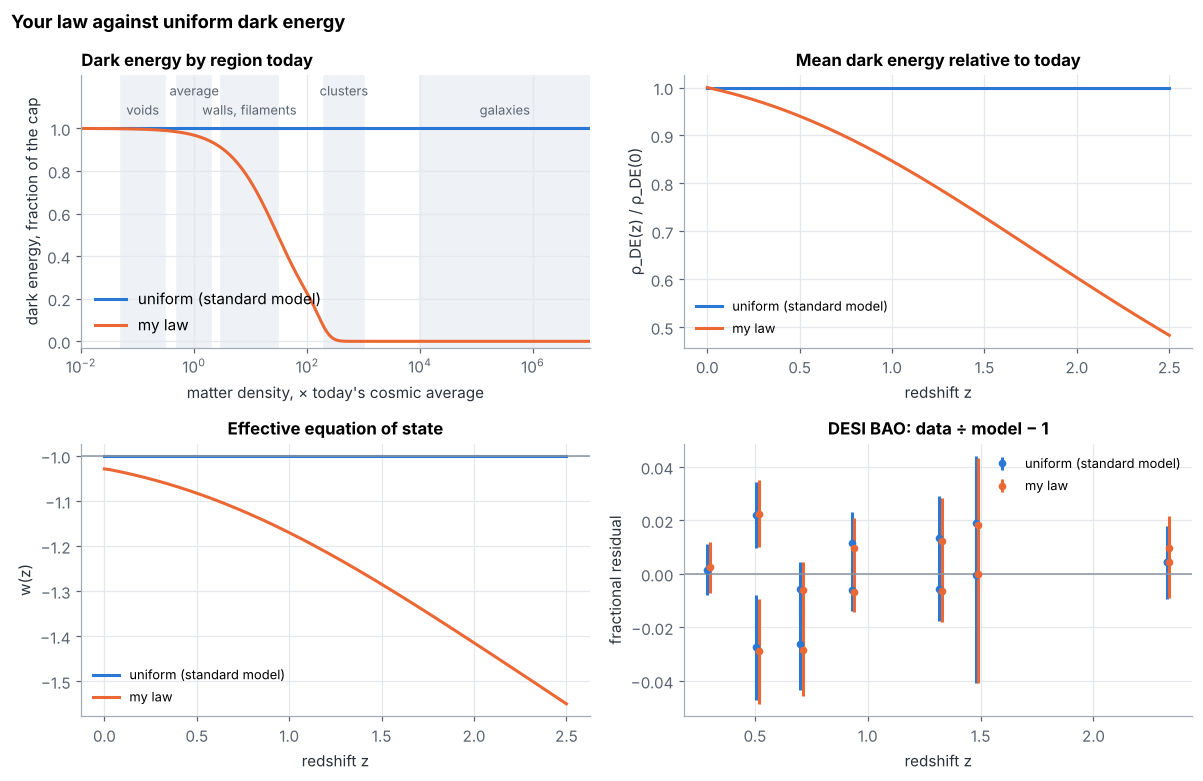

In [8]:
def evaluate(law, fit_to=("sn", "bao")):
    lm = LawModel(law)
    fit = fit_expansion(lm, use_sn="sn" in fit_to, use_bao="bao" in fit_to)
    f, D = growth(lm, fit["Om"])
    k_pred = f * D / REF_FD
    out = dict(law=law.name, x_half=law.x_half, n=law.n, x_cut=law.x_cut, p=law.p, **fit,
               k_pred=float(k_pred), chi2_vel=float(((k_pred - VEL["k"]) / VEL["k_err"]) ** 2),
               kappa0=float(lm.kappa_web[0]), w0=float(lm.w_eff(0.0)), w1=float(lm.w_eff(1.0)),
               de_z1=float(lm.f(1.0)), void_vs_average=float(law.shape(0.2) / law.shape(1.0) - 1))
    return out, lm

BASE, _ = evaluate(UNIFORM)

def verdict(d):
    if d < -4: return "better than uniform dark energy (over 2σ)"
    if d <= 4: return "about as good as uniform dark energy"
    if d <= 25: return "disfavoured"
    return "ruled out"

def scorecard(law, show=True):
    r, lm = evaluate(law)
    d_exp = r["chi2_exp"] - BASE["chi2_exp"]; d_vel = r["chi2_vel"] - BASE["chi2_vel"]
    r.update(d_exp=d_exp, d_vel=d_vel, d_total=d_exp + d_vel)
    if show:
        print(f"{law.name}:  x_half = {law.x_half:g}, n = {law.n:g}, x_cut = {law.x_cut:g}, p = {law.p:g}")
        print(f"  Expansion   Δχ² = {d_exp:+7.2f}  (supernovae {r['chi2_sn'] - BASE['chi2_sn']:+.2f}, BAO {r['chi2_bao'] - BASE['chi2_bao']:+.2f}) -> {verdict(d_exp)}")
        print(f"  Motions     predicted slope {r['k_pred']:.2f} vs measured {VEL['k']:.2f} ± {VEL['k_err']:.2f}  (Δχ² = {d_vel:+.2f})")
        print(f"  Combined    Δχ² = {d_exp + d_vel:+7.2f} -> {verdict(d_exp + d_vel)}")
        print(f"  Fitted      Ωm = {r['Om']:.3f}, H0 = {r['H0']:.2f} km/s/Mpc")
        print(f"  Over time   mean dark energy at z = 1 is {r['de_z1']:.3f}× today's; w(z=0) = {r['w0']:.3f}, w(z=1) = {r['w1']:.3f}")
        print(f"  Lumpiness   κ today = {r['kappa0']:.3f}; a deep void carries {100 * r['void_vs_average']:+.2f}% more dark energy than an average patch")
        today = pd.Series(law.shape(list(REGIONS.values())) / lm.mean_S0, index=REGIONS.keys())
        print("  Dark energy today relative to the cosmic mean: " + ", ".join(f"{k} {v:.3f}" for k, v in today.items()))
    return r

def compare(laws, title="Laws compared", save=None):
    fig, axs = plt.subplots(2, 2, figsize=(11, 7.2))
    plot_shapes(laws, axs[0, 0]); axs[0, 0].set_title("Dark energy by region today", loc="left")
    zz = np.linspace(0, 2.5, 200)
    for law, c in zip(laws, LAW_COLOURS):
        lm = LawModel(law); fit = fit_expansion(lm)
        axs[0, 1].plot(zz, lm.f(zz), color=c, label=law.name)
        axs[1, 0].plot(zz, lm.w_eff(zz), color=c, label=law.name)
        ratio = BAO.chi2(lm, fit["Om"], details=True)[1]["ratio"]
        off = (LAW_COLOURS.index(c) - (len(laws) - 1) / 2) * 0.012
        axs[1, 1].errorbar(BAO.z + off, ratio - 1, yerr=BAO.err / BAO.d, fmt="o", ms=4, color=c, capsize=0, label=law.name)
    axs[0, 1].set(title="Mean dark energy relative to today", xlabel="redshift z", ylabel="ρ_DE(z) / ρ_DE(0)")
    axs[1, 0].set(title="Effective equation of state", xlabel="redshift z", ylabel="w(z)")
    axs[1, 0].axhline(-1, color=COL["muted"], lw=1)
    axs[1, 1].axhline(0, color=COL["muted"], lw=1)
    axs[1, 1].set(title="DESI BAO: data ÷ model − 1", xlabel="redshift z", ylabel="fractional residual")
    for ax in axs.flat[1:]: ax.legend(fontsize=8.5)
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold"); fig.tight_layout()
    if save: fig.savefig(OUT / save, bbox_inches="tight")
    plt.show()

my_score = scorecard(MY_LAW)
compare([UNIFORM, MY_LAW], title="Your law against uniform dark energy", save="my_law.png")

## 7. Galaxies stay untouched

Inside a galaxy the outward push of dark energy, relative to the gravity that holds the orbit, is $2\rho_{\rm DE}/\rho_{\rm dyn}$, where $\rho_{\rm dyn} = 3v^2/(4\pi G r^2)$ is the mean density enclosed by the orbit. This cell evaluates it at the outermost measured point of every SPARC galaxy, where dark energy has the best chance to matter.

Your own galaxy run found the same thing from the other side: its density-screened Λ model scored exactly like visible matter alone.

175 galaxies; matter density at their last measured radius: median 7.6e+04× the cosmic average (lowest 5.21e+03×)
push ÷ gravity there, uniform dark energy: median 5.7e-05, largest 8.4e-04
push ÷ gravity there, my law: median 3.2e-74, largest 9.2e-27


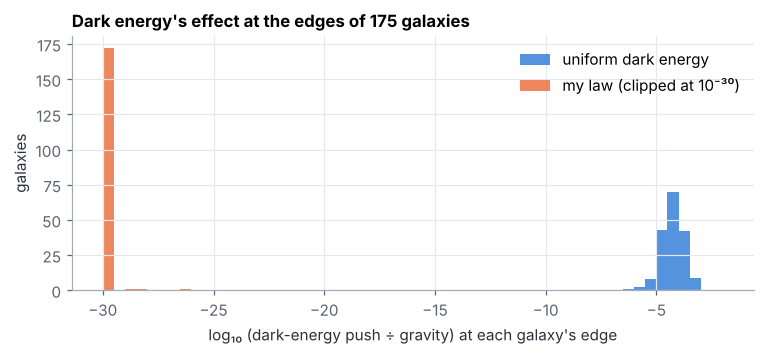

In [9]:
def load_sparc_edges(folder):
    rows = []
    for fn in sorted(Path(folder).glob("*_rotmod.dat")):
        a = np.loadtxt(fn, comments="#", ndmin=2)
        a = a[(a[:, 0] > 0) & (a[:, 1] > 0)]
        if len(a):
            k = int(np.argmax(a[:, 0]))
            rows.append(dict(galaxy=fn.name.replace("_rotmod.dat", ""), r_kpc=a[k, 0], v_kms=a[k, 1]))
    return pd.DataFrame(rows)

def galaxy_check(law, show=True):
    if SPARC_DIR is None:
        print("SPARC not available; skipping the galaxy check"); return None
    lm = LawModel(law); fit = fit_expansion(lm)
    rho_c = 3 * (fit["H0"] * 1e3 / MPC_M) ** 2 / (8 * math.pi * G_SI)
    rho_de_mean = (1 - fit["Om"]) * rho_c; rho_cap = rho_de_mean / lm.mean_S0
    g = load_sparc_edges(SPARC_DIR)
    rho_dyn = 3 * (g.v_kms * 1e3) ** 2 / (4 * math.pi * G_SI * (g.r_kpc * KPC_M) ** 2)
    g["density_x"] = rho_dyn / (fit["Om"] * rho_c)
    g["uniform_ratio"] = 2 * rho_de_mean / rho_dyn
    g["law_ratio"] = 2 * rho_cap * law.shape(g.density_x) / rho_dyn
    if show:
        print(f"{len(g)} galaxies; matter density at their last measured radius: median {g.density_x.median():.3g}× the cosmic average "
              f"(lowest {g.density_x.min():.3g}×)")
        print(f"push ÷ gravity there, uniform dark energy: median {g.uniform_ratio.median():.1e}, largest {g.uniform_ratio.max():.1e}")
        print(f"push ÷ gravity there, {law.name}: median {g.law_ratio.median():.1e}, largest {g.law_ratio.max():.1e}")
        fig, ax = plt.subplots(figsize=(8, 3))
        bins = np.linspace(-30, -2, 57)
        ax.hist(np.log10(np.clip(g.uniform_ratio, 1e-30, None)), bins=bins, color=COL["uniform"], alpha=0.8, label="uniform dark energy")
        ax.hist(np.log10(np.clip(g.law_ratio, 1e-30, None)), bins=bins, color=COL["law"], alpha=0.8, label=law.name + " (clipped at 10⁻³⁰)")
        ax.set(xlabel="log₁₀ (dark-energy push ÷ gravity) at each galaxy's edge", ylabel="galaxies")
        ax.set_title("Dark energy's effect at the edges of 175 galaxies", loc="left"); ax.legend(); plt.show()
    return g

_ = galaxy_check(MY_LAW)

## 8. What the law predicts for voids

For voids with a given radius and emptiness (density contrast δ inside the radius), the table compares the uniform model with your law:

* dark energy inside the void relative to the cosmic mean,
* how fast the void's edge moves outward in linear theory, $v = \tfrac{f}{3}H_0|\delta|R$,
* how much faster than average the void expands inside, $f|\delta|/3$.

Edit `VOIDS` to try your own sizes and depths.

In [10]:
VOIDS = [(10, -0.8), (30, -0.5), (100, -0.2)]      # (radius in Mpc, density contrast inside)

def void_table(law, voids=VOIDS):
    lm = LawModel(law); fit = fit_expansion(lm); f_law, _ = growth(lm, fit["Om"])
    f_uni, _ = growth(UNI, BASE["Om"])
    rows = []
    for R, d in voids:
        rows.append({"radius (Mpc)": R, "density contrast": d,
                     "dark energy inside ÷ mean": round(float(law.shape(1 + d) / lm.mean_S0), 4),
                     "edge outflow, uniform (km/s)": round(f_uni / 3 * BASE["H0"] * abs(d) * R),
                     "edge outflow, law (km/s)": round(f_law / 3 * fit["H0"] * abs(d) * R),
                     "faster expansion inside, uniform": f"+{100 * f_uni * abs(d) / 3:.1f}%",
                     "faster expansion inside, law": f"+{100 * f_law * abs(d) / 3:.1f}%"})
    return pd.DataFrame(rows)

void_table(MY_LAW)

,radius (Mpc),density contrast,dark energy inside ÷ mean,"edge outflow, uniform (km/s)","edge outflow, law (km/s)","faster expansion inside, uniform","faster expansion inside, law"
0,10,-0.8,1.0234,102,109,+13.8%,+14.8%
1,30,-0.5,1.0134,191,205,+8.6%,+9.3%
2,100,-0.2,1.0035,254,273,+3.4%,+3.7%


## 9. Searching for the law

### 9a. Shape: how low a threshold, how sharp a switch?

A grid over `x_half` (1 to 10,000× the mean) and `n` (0.5 to 4), with `x_cut` and `p` held at your values. Each square is the combined Δχ² against uniform dark energy, with $\Omega_m$ re-fitted for every square. Contours mark 2σ (Δχ² = 4) and 5σ (25). The cutoff barely matters here because less than 0.1% of the volume is denser than 30×; it decides only where galaxies and clusters switch dark energy off.

scored 175 laws in 8.6 s


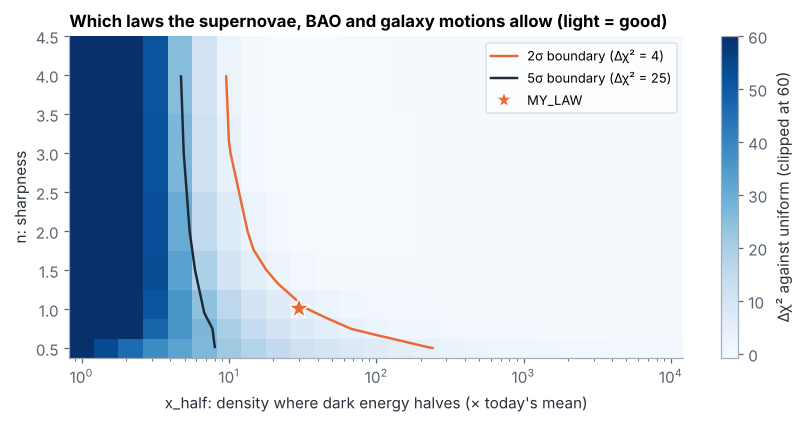

111 of 175 laws are within 2σ of uniform dark energy.
Lowest allowed threshold for each sharpness:  n = 0.5: x_half ≥ 316,  n = 0.75: x_half ≥ 68.1,  n = 1: x_half ≥ 46.4,  n = 1.5: x_half ≥ 21.5,  n = 2: x_half ≥ 14.7,  n = 3: x_half ≥ 14.7,  n = 4: x_half ≥ 10
Largest extra dark energy in a deep void among allowed laws: 3.03% over an average patch.


,x_half,n,d_total,d_exp,d_vel,w1,void_vs_average,Om
69,31.622777,4.0,-0.747741,-1.583420,0.835679,-1.078336,9.984000e-07,0.312261
62,21.544347,4.0,-0.728274,-2.102281,1.374007,-1.151037,4.634162e-06,0.316232
68,31.622777,3.0,-0.635569,-1.534086,0.898517,-1.090924,3.136979e-05,0.312601
76,46.415888,4.0,-0.532745,-1.029099,0.496355,-1.036666,2.150988e-07,0.308988
75,46.415888,3.0,-0.525324,-1.070781,0.545457,-1.046435,9.919999e-06,0.309461
61,21.544347,3.0,-0.407044,-1.857220,1.450177,-1.163863,9.919992e-05,0.316349
82,68.129207,3.0,-0.323158,-0.651679,0.328520,-1.021799,3.136979e-06,0.307182
83,68.129207,4.0,-0.280989,-0.573440,0.292451,-1.015416,4.634162e-08,0.306720


In [11]:
def scan(base_law=MY_LAW, x_halfs=np.geomspace(1, 1e4, 25), ns=(0.5, 0.75, 1, 1.5, 2, 3, 4)):
    rows = []
    t0 = time.time()
    for xh in x_halfs:
        for n in ns:
            rows.append(scorecard(replace(base_law, x_half=float(xh), n=float(n), name=f"x_half={xh:.3g}, n={n}"), show=False))
    print(f"scored {len(rows)} laws in {time.time() - t0:.1f} s")
    return pd.DataFrame(rows)

grid = scan()
grid.to_csv(OUT / "law_scan.csv", index=False)

piv = grid.pivot(index="n", columns="x_half", values="d_total")
def _edges(v, log):
    v = np.log10(v) if log else np.asarray(v, float)
    mid = (v[1:] + v[:-1]) / 2
    e = np.concatenate([[v[0] - (mid[0] - v[0])], mid, [v[-1] + (v[-1] - mid[-1])]])
    return 10 ** e if log else e
fig, ax = plt.subplots(figsize=(9, 3.8))
mesh = ax.pcolormesh(_edges(piv.columns.to_numpy(), True), _edges(piv.index.to_numpy(), False),
                     np.clip(piv.values, -5, 60), cmap="Blues", shading="flat")
ax.contour(piv.columns, piv.index, piv.values, levels=[4, 25], colors=["#eb6834", "#1f2933"], linewidths=1.6)
ax.plot(MY_LAW.x_half, MY_LAW.n, marker="*", ms=15, color="#eb6834", mec="white", ls="none")
ax.grid(False)
ax.legend(handles=[plt.Line2D([], [], color="#eb6834", lw=1.6, label="2σ boundary (Δχ² = 4)"),
                   plt.Line2D([], [], color="#1f2933", lw=1.6, label="5σ boundary (Δχ² = 25)"),
                   plt.Line2D([], [], color="#eb6834", marker="*", ms=12, mec="white", ls="none", label="MY_LAW")],
          loc="upper right", fontsize=8.5, frameon=True, facecolor="white", edgecolor="#d5dae0")
ax.set_xscale("log"); ax.set_xlabel("x_half: density where dark energy halves (× today's mean)"); ax.set_ylabel("n: sharpness")
fig.colorbar(mesh, label="Δχ² against uniform (clipped at 60)")
ax.set_title("Which laws the supernovae, BAO and galaxy motions allow (light = good)", loc="left")
fig.savefig(OUT / "law_scan.png", bbox_inches="tight"); plt.show()

ok = grid[grid.d_total < 4]
print(f"{len(ok)} of {len(grid)} laws are within 2σ of uniform dark energy.")
print("Lowest allowed threshold for each sharpness:  " +
      ",  ".join(f"n = {n:g}: x_half ≥ {xh:.3g}" for n, xh in ok.groupby("n").x_half.min().items()))
print(f"Largest extra dark energy in a deep void among allowed laws: {100 * ok.void_vs_average.max():.2f}% over an average patch.")
grid.sort_values("d_total").head(8)[["x_half", "n", "d_total", "d_exp", "d_vel", "w1", "void_vs_average", "Om"]]

### 9b. Compounding: does empty space grow exactly in proportion to its volume?

With the shape switched off (uniform), scan the compounding exponent $p$. The square-root law, $p = 0.5$, is far off this chart: it behaves like ordinary matter and gives no acceleration at all. The split by dataset shows which data drive any preference.

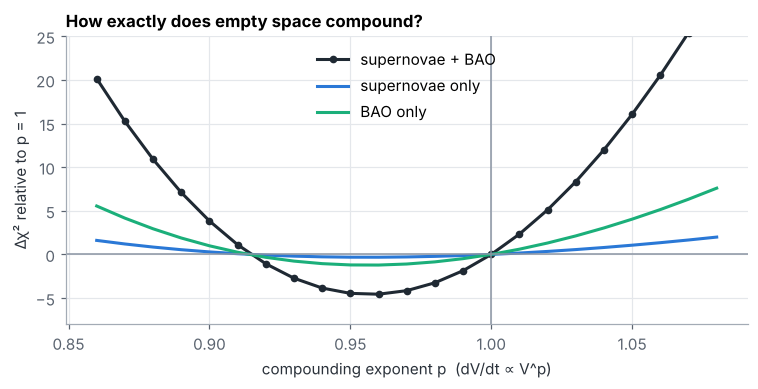

best p = 0.96 (equivalent to a constant w = -0.92); Δχ² against p = 1: -4.56


In [12]:
ps = np.round(np.arange(0.86, 1.081, 0.01), 3)
rows = []
for p in ps:
    lm = LawModel(replace(UNIFORM, p=p))
    both, sn, bao = fit_expansion(lm), fit_expansion(lm, use_bao=False), fit_expansion(lm, use_sn=False)
    rows.append(dict(p=p, both=both["chi2_exp"], sn=sn["chi2_sn"], bao=bao["chi2_bao"]))
pscan = pd.DataFrame(rows)
for col in ("both", "sn", "bao"):
    pscan[col] -= float(pscan.loc[np.isclose(pscan.p, 1.0), col].iloc[0])
best_p = float(pscan.p[pscan.both.idxmin()])

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(pscan.p, pscan.both, color=COL["data"], marker="o", ms=4, label="supernovae + BAO")
ax.plot(pscan.p, pscan.sn, color=COL["uniform"], label="supernovae only")
ax.plot(pscan.p, pscan.bao, color=COL["alt"], label="BAO only")
ax.axhline(0, color=COL["muted"], lw=1); ax.axvline(1, color=COL["muted"], lw=1)
ax.set(xlabel="compounding exponent p  (dV/dt ∝ V^p)", ylabel="Δχ² relative to p = 1", ylim=(-8, 25))
ax.set_title("How exactly does empty space compound?", loc="left"); ax.legend()
fig.savefig(OUT / "compounding_scan.png", bbox_inches="tight"); plt.show()
print(f"best p = {best_p:.2f} (equivalent to a constant w = {1 - 2 * best_p:.2f}); Δχ² against p = 1: {pscan.both.min():+.2f}")

### 9c. Let the data choose

A direct fit of `x_half`, `n` and `p` together, with `x_cut` held fixed. If the best `x_half` runs to the top of its range, the data are asking for no density dependence at all.

fit took 28 s

best fit:  x_half = 15093.3, n = 2.41487, x_cut = 200, p = 0.956237
  Expansion   Δχ² =   -4.56  (supernovae -2.73, BAO -1.83) -> better than uniform dark energy (over 2σ)
  Motions     predicted slope 0.94 vs measured 0.88 ± 0.16  (Δχ² = -0.20)
  Combined    Δχ² =   -4.76 -> better than uniform dark energy (over 2σ)
  Fitted      Ωm = 0.298, H0 = 73.43 km/s/Mpc
  Over time   mean dark energy at z = 1 is 1.199× today's; w(z=0) = -0.912, w(z=1) = -0.913
  Lumpiness   κ today = 0.000; a deep void carries +0.00% more dark energy than an average patch
  Dark energy today relative to the cosmic mean: empty space (the cap) 1.000, deep void 1.000, average patch 1.000, wall 1.000, filament 1.000, cluster 0.004, galaxy disc 0.000


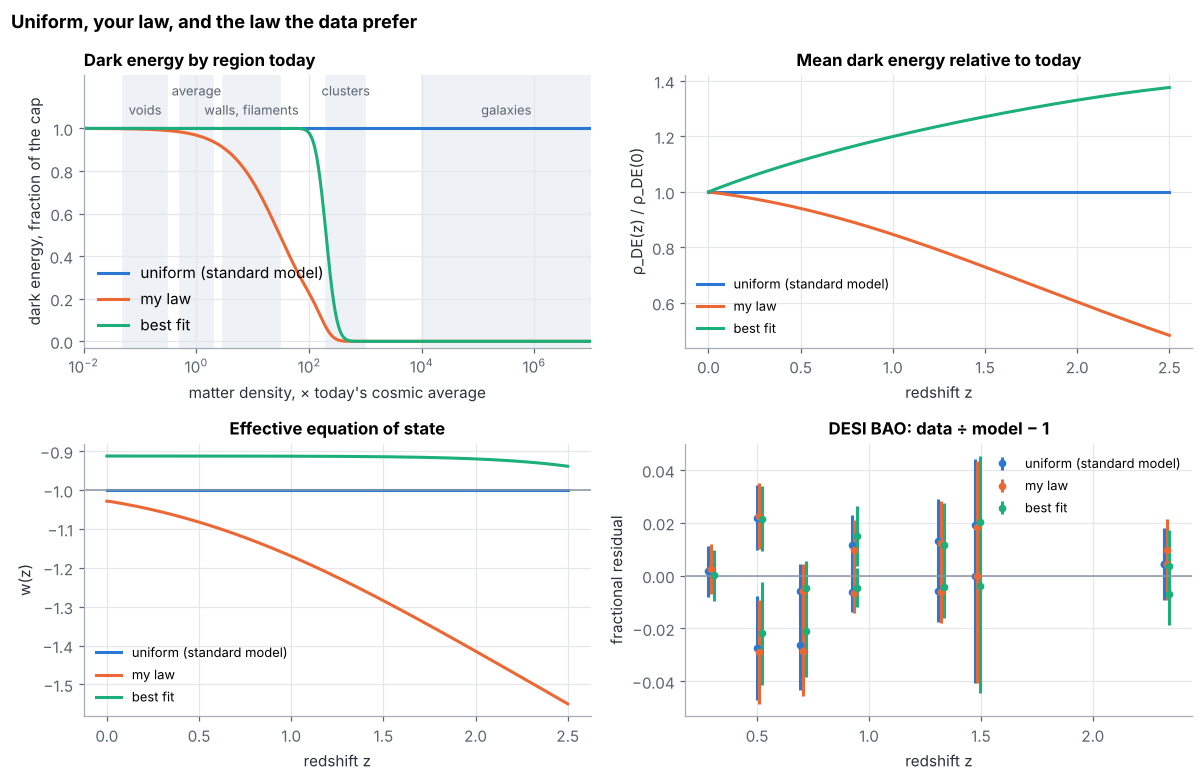

In [13]:
def fit_law(start=MY_LAW, free=("x_half", "n", "p"), bounds=None):
    bounds = bounds or dict(x_half=(0.0, 5.0), n=(0.3, 6.0), p=(0.7, 1.2), x_cut=(1.0, 6.0))   # x_half, x_cut in log10
    logged = {"x_half", "x_cut"}
    def unpack(th):
        kw = {}
        for name, val in zip(free, th):
            lo, hi = bounds[name]
            if not lo <= val <= hi:
                return None
            kw[name] = 10 ** val if name in logged else val
        return replace(start, name="best fit", **kw)
    def objective(th):
        law = unpack(th)
        return 1e6 if law is None else scorecard(law, show=False)["d_total"]
    x0 = [math.log10(getattr(start, k)) if k in logged else getattr(start, k) for k in free]
    best = None
    for jitter in ([0, 0, 0], [0.5, 0.5, -0.03], [1.5, 0.0, -0.05], [-0.5, 1.0, 0.0]):
        x = [v + j for v, j in zip(x0, jitter[:len(x0)])]
        res = optimize.minimize(objective, x, method="Nelder-Mead", options=dict(xatol=1e-3, fatol=1e-3, maxiter=400))
        if best is None or res.fun < best.fun:
            best = res
    law = unpack(best.x)
    edge = [k for k, v in zip(free, best.x) if abs(v - bounds[k][1]) < 0.02 or abs(v - bounds[k][0]) < 0.02]
    if edge:
        print("at the edge of its range:", ", ".join(edge))
    return law

t0 = time.time()
BEST = fit_law()
print(f"fit took {time.time() - t0:.0f} s\n")
best_score = scorecard(BEST)
compare([UNIFORM, MY_LAW, BEST], title="Uniform, your law, and the law the data prefer", save="best_law.png")

## 10. Try your own law

Subclass `DarkEnergyLaw` and override `shape(x)`. It must return a value between 0 and 1 for any array of densities `x` (in units of today's mean), with 1 meaning the cap. Everything else, including the scan and the fit, then works unchanged.

The example below is an exponential fall with a hard stop.

In [14]:
@dataclass
class ExponentialLaw(DarkEnergyLaw):
    name: str = "exponential with a hard stop"

    def shape(self, x):
        x = np.maximum(np.asarray(x, dtype=float), 0.0)
        s = np.exp(-x / self.x_half)
        return np.where(x < self.x_cut, s, 0.0)

my_exp = ExponentialLaw(x_half=100.0, x_cut=200.0)
_ = scorecard(my_exp)

exponential with a hard stop:  x_half = 100, n = 1, x_cut = 200, p = 1
  Expansion   Δχ² =   +0.32  (supernovae +0.18, BAO +0.15) -> about as good as uniform dark energy
  Motions     predicted slope 1.04 vs measured 0.88 ± 0.16  (Δχ² = +0.71)
  Combined    Δχ² =   +1.03 -> about as good as uniform dark energy
  Fitted      Ωm = 0.310, H0 = 73.76 km/s/Mpc
  Over time   mean dark energy at z = 1 is 0.936× today's; w(z=0) = -1.010, w(z=1) = -1.074
  Lumpiness   κ today = 0.010; a deep void carries +0.80% more dark energy than an average patch
  Dark energy today relative to the cosmic mean: empty space (the cap) 1.010, deep void 1.008, average patch 1.000, wall 0.980, filament 0.914, cluster 0.000, galaxy disc 0.000


## 11. Your galaxy-side run (optional)

If you unzip `results_to_share.zip` next to this notebook (into a folder called `results_to_share`), this cell shows its cross-validated scores alongside the work here. Keep the 30 reserved test galaxies sealed until you've frozen a law.

In [15]:
bundle = Path("results_to_share")
if (bundle / "metrics.csv").exists():
    m = pd.read_csv(bundle / "metrics.csv")
    display(m.pivot(index="model", columns="subset", values="rms_log10_speed_dex").sort_values("outer").round(3))
    print(pd.read_csv(bundle / "paired_bootstrap.csv").to_string(index=False))
else:
    print("No results_to_share/ folder found next to the notebook; skipping.")

subset,all,outer
model,,
rar,0.076,0.067
density_gradient,0.186,0.126
shared_nfw,0.131,0.133
radius_gradient,0.136,0.138
screened_lambda,0.201,0.220
baryons,0.201,0.220


subset       reference                         status  galaxies  candidate_minus_reference_dex  bootstrap_p025_dex  bootstrap_p975_dex  bootstrap_fraction_below_zero
   all         baryons ineligible_invalid_predictions       NaN                            NaN                 NaN                 NaN                            NaN
   all             rar ineligible_invalid_predictions       NaN                            NaN                 NaN                 NaN                            NaN
   all radius_gradient ineligible_invalid_predictions       NaN                            NaN                 NaN                 NaN                            NaN
 outer         baryons                             ok     103.0                      -0.093873           -0.117639           -0.070571                          1.000
 outer             rar                             ok     103.0                       0.059092            0.038944            0.080674                          0.000
 out

## 12. The microwave background (CMB)

The CMB fixes the distance to the moment the universe became transparent ($z \approx 1090$), measured in units of the sound horizon, together with the matter density. For dark-energy models that leave the early universe alone, Planck's full likelihood compresses into three numbers (Planck 2018 distance priors, Zhai & Wang 2019): the shift parameter $R$, the acoustic scale $\ell_A$ and the baryon density $\omega_b$, with their covariance.

Two practical points:

* The decoupling redshift $z_*$ comes from the Hu & Sugiyama (1996) fitting formula. It lands about 2 above Planck's full calculation, which on its own would shift $\ell_A$ by 5σ. The cell calibrates this once, so Planck's best-fit standard model reproduces Planck's three numbers exactly. Differences between dark-energy models then come from the distance integral, which is computed exactly.
* The CMB gets its own $h$ and $\omega_b$. Supernovae keep their own scale and BAO its free amplitude, so the Hubble tension doesn't leak into the comparison. DESI combines uncalibrated supernovae with the CMB the same way.

In [16]:
OMEGA_GAMMA = 2.469e-5                                   # photon density ω_γ for T_CMB = 2.7255 K
OMEGA_R = OMEGA_GAMMA * (1 + 0.2271 * 3.046)             # photons plus 3.046 neutrino species
CMB_MEAN = np.array([1.74963, 301.80845, 0.02237])       # R, l_A, ω_b (Planck 2018; Zhai & Wang 2019)
CMB_COV = 1e-8 * np.array([[1598.9554, 17112.007, -36.311179],
                           [17112.007, 811208.45, -494.79813],
                           [-36.311179, -494.79813, 2.1242182]])
CMB_W = np.linalg.inv(CMB_COV)
_X = np.linspace(0.0, 1.0, 3001)

def z_star(wb, wm):
    """Decoupling redshift, Hu & Sugiyama (1996) fitting formula."""
    g1 = 0.0783 * wb ** -0.238 / (1 + 39.5 * wb ** 0.763)
    g2 = 0.560 / (1 + 21.1 * wb ** 1.81)
    return 1048 * (1 + 0.00124 * wb ** -0.738) * (1 + g1 * wm ** g2)

def _cmb_raw(hist, Om, h, wb):
    Or = OMEGA_R / h ** 2
    lzs = math.log1p(z_star(wb, Om * h * h))
    E = lambda z: np.sqrt(Om * (1 + z) ** 3 + Or * (1 + z) ** 4 + (1 - Om - Or) * hist.f(z))
    x = _X * lzs; z = np.expm1(x)
    DM = integrate.trapezoid((1 + z) / E(z), x)                                 # distance to z*, units of c/H0
    x2 = lzs + _X * (math.log(1e8) - lzs); z2 = np.expm1(x2)
    Rb = 3 * wb / (4 * OMEGA_GAMMA * (1 + z2))                                  # baryon loading of the photon fluid
    rs = integrate.trapezoid((1 + z2) / (E(z2) * np.sqrt(3 * (1 + Rb))), x2)    # sound horizon at z*
    return np.array([math.sqrt(Om) * DM, math.pi * DM / rs, wb])

CMB_CAL = CMB_MEAN / _cmb_raw(UNI, 0.3153, 0.6736, 0.02237)                    # one-off calibration at Planck's best fit

def cmb_chi2(hist, Om, h, wb):
    d = _cmb_raw(hist, Om, h, wb) * CMB_CAL - CMB_MEAN
    return float(d @ CMB_W @ d)

print(f"fitting-formula z* at Planck's best fit: {z_star(0.02237, 0.3153 * 0.6736 ** 2):.1f} (Planck's full calculation: 1089.9)")
print(f"calibration applied to R and l_A: ×{CMB_CAL[0]:.5f}, ×{CMB_CAL[1]:.5f}")

fitting-formula z* at Planck's best fit: 1091.9 (Planck's full calculation: 1089.9)
calibration applied to R and l_A: ×1.00000, ×0.99844


## 13. Any dark-energy history, fitted with everything

Sections 2–9 work with density laws. This section accepts **any history**: a `History` is just the mean dark energy relative to today, $f(z) = \bar\rho_{\rm DE}(z)/\bar\rho_{\rm DE}(0)$, plus (optionally) how strongly dark energy follows matter in space.

* `cpl(w0, wa)` is DESI's evolving dark energy, $w(z) = w_0 + w_a z/(1+z)$.
* `from_law(law)` turns a density law into a history in which each patch of space responds to its **own** density (section 3's web), lumps included.
* `average_density(law)` uses the same law but lets dark energy respond to the **universe's mean density** only, $\bar\rho_{\rm DE} \propto \rho_{\rm cap}(z)\,S\big((1+z)^3\big)$. Dark energy then switches on as the whole universe thins out and stays smooth in space.
* `fit_family(make, starts, bounds, use)` fits $\Omega_m$ (plus the CMB's $h$ and $\omega_b$) and the family's own parameters, on any mix of `"sn"`, `"bao"`, `"vel"` (galaxy flows) and `"cmb"`.
* `scoreboard(families, use)` fits a set of families on the same data. The first family is the reference.

In [17]:
class History:
    """Any dark-energy history. f: mean dark energy relative to today, on a redshift grid.
    g: kappa × f, how much dark energy follows matter in space (None = smooth)."""
    def __init__(self, z, f, g=None, name=""):
        self._lz = np.log1p(z); self.name = name
        self.f_web = np.maximum(np.asarray(f, float), 0.0)
        self.g_web = np.zeros_like(self.f_web) if g is None else np.asarray(g, float)
        self.f_grid = self.f(Z_GRID)
    def f(self, z): return np.interp(np.log1p(z), self._lz, self.f_web)
    def g(self, z): return np.interp(np.log1p(z), self._lz, self.g_web)
    def w_eff(self, z):
        dlnf = np.gradient(np.log(np.maximum(self.f_web, 1e-300)), self._lz)
        return -1 + np.interp(np.log1p(z), self._lz, dlnf) / 3

ZH = np.concatenate([np.linspace(0, 3, 301), np.geomspace(3, 1e8, 400)[1:]])

def cpl(w0, wa, name=None):
    """Smooth dark energy with w(z) = w0 + wa z/(1+z). w0 = -1, wa = 0 is the standard model."""
    if w0 + wa >= 0:
        raise ValueError("w0 + wa must be negative")
    f = (1 + ZH) ** (3 * (1 + w0 + wa)) * np.exp(-3 * wa * ZH / (1 + ZH))
    return History(ZH, f, name=name or f"w0 = {w0:.2f}, wa = {wa:.2f}")

def from_law(law):
    """Each patch responds to its own density: mean history from the web, plus the lumps."""
    lm = LawModel(law)
    z = np.concatenate([lm.web_z, np.geomspace(lm.web_z[-1] * 1.01, 1e8, 50)])
    f = np.concatenate([lm.f_web, np.full(50, lm.f_web[-1])])
    g = np.concatenate([lm.g_web, np.full(50, lm.g_web[-1])])
    return History(z, f, g, name=law.name)

def average_density(law):
    """Dark energy set by the universe's mean matter density only, xbar = (1+z)^3; smooth in space."""
    S0 = float(law.shape(1.0))
    if not S0 > 0:
        raise ValueError("the law leaves no dark energy at today's mean density")
    f = (1 + ZH) ** (6 * (1 - law.p)) * law.shape((1 + ZH) ** 3) / S0
    return History(ZH, f, name=law.name + " (average density)")

def chi2_parts(hist, Om, h=None, wb=None, use=("sn", "bao", "vel", "cmb")):
    out = {}
    if "sn" in use: out["sn"] = SN.chi2(hist, Om)
    if "bao" in use: out["bao"] = BAO.chi2(hist, Om)
    if "vel" in use:
        f, D = growth(hist, Om)
        out["k_pred"] = f * D / REF_FD
        out["vel"] = ((out["k_pred"] - VEL["k"]) / VEL["k_err"]) ** 2
    if "cmb" in use: out["cmb"] = cmb_chi2(hist, Om, h, wb)
    return out

def fit_family(make, starts, bounds=(), use=("sn", "bao", "vel", "cmb")):
    """make(*params) -> History. starts: list of [Ωm, params...]. bounds: (lo, hi) per param.
    Flows join in a final polish, which keeps the fit fast."""
    use_all, with_cmb = tuple(use), "cmb" in use
    stage = {"use": tuple(u for u in use_all if u != "vel")}
    def obj(th):
        Om, rest = th[0], list(th[1:])
        h = wb = None
        if with_cmb:
            h, wb, rest = rest[0], rest[1], rest[2:]
            if not (0.5 < h < 0.9 and 0.019 < wb < 0.026):
                return 1e9
        if not 0.05 < Om < 0.7 or any(not lo <= v <= hi for v, (lo, hi) in zip(rest, bounds)):
            return 1e9
        try:
            hist = make(*rest)
        except (ValueError, FloatingPointError, OverflowError):
            return 1e9
        return sum(v for k, v in chi2_parts(hist, Om, h, wb, stage["use"]).items() if k != "k_pred")
    best = None
    for s in starts:
        x0 = [s[0]] + ([0.674, 0.02237] if with_cmb else []) + list(s[1:])
        r = optimize.minimize(obj, x0, method="Nelder-Mead", options=dict(xatol=1e-6, fatol=1e-6, maxfev=3000, adaptive=True))
        if best is None or r.fun < best.fun:
            best = r
    if "vel" in use_all:
        stage["use"] = use_all
        best = optimize.minimize(obj, best.x, method="Nelder-Mead", options=dict(xatol=1e-6, fatol=1e-6, maxfev=1200, adaptive=True))
    th = list(best.x); Om = th[0]
    h, wb, rest = (th[1], th[2], th[3:]) if with_cmb else (None, None, th[1:])
    hist = make(*rest)
    return dict(chi2=best.fun, Om=Om, h=h, wb=wb, params=rest, hist=hist, parts=chi2_parts(hist, Om, h, wb, use_all))

def scoreboard(families, use=("sn", "bao", "vel", "cmb")):
    """families: {name: (make, starts, bounds, param_names)}. The first family is the reference."""
    rows, fits = [], {}
    for name, (make, starts, bounds, pnames) in families.items():
        t0 = time.time()
        r = fit_family(make, starts, bounds, use); fits[name] = r
        rows.append({"model": name, "extra numbers": len(pnames), "χ²": r["chi2"],
                     "best-fit parameters": ", ".join(f"{k} = {v:.3g}" for k, v in zip(pnames, r["params"])) or "—",
                     "Ωm": round(r["Om"], 3), "flow slope": round(r["parts"].get("k_pred", np.nan), 2),
                     "w today": round(float(r["hist"].w_eff(0.0)), 3), "seconds": round(time.time() - t0)})
    df = pd.DataFrame(rows)
    df.insert(2, "Δχ² vs reference", (df["χ²"] - df["χ²"].iloc[0]).round(2))
    return df.drop(columns=["χ²"]).set_index("model"), fits

_check = fit_family(lambda: UNI, [[0.31]], (), use=("cmb",))
print(f"standard model from the CMB alone: Ωm = {_check['Om']:.4f}, h = {_check['h']:.4f}, ωb = {_check['wb']:.5f} "
      "(Planck 2018: 0.3153, 0.6736, 0.02237)")

standard model from the CMB alone: Ωm = 0.3153, h = 0.6736, ωb = 0.02237 (Planck 2018: 0.3153, 0.6736, 0.02237)


## 14. Surface growth

**Smooth surface.** If empty space grows only through its surface, $dV/dt = \alpha S \propto V^{2/3}$, so $p = 2/3$. The growth per cubic metre then falls as one over the region's size, which gives $w = -1/3$: expansion that never accelerates.

**Rough surface.** A crumpled surface of dimension $D$ has an area that scales as $R^D \propto V^{D/3}$, so $p = D/3$ and $w = 1 - 2D/3$. $D = 2$ is a smooth surface and $D = 3$ fills the whole volume, which is the standard model.

**Void-surface law.** Empty space grows through the boundaries of genuinely empty regions: $dV_{\rm void}/dt = \alpha\,S_{\rm void}$. Structure formation creates new void boundary as matter drains into walls, and expansion stretches it out (area per volume falls as $1/a$). In the lognormal web, the boundary area per volume of regions emptier than $x_{\rm void}$ times the mean follows the Rice formula, $S_V \propto e^{-\nu^2/2}$ with $\nu = (\ln x_{\rm void} + s^2/2)/s$, where $s(z)$ is the web's log-density spread at cell size $R$. Then $H_{\rm DE} \propto S_V\,(1+z)$ and $\rho_{\rm DE} \propto H_{\rm DE}^2$. The two knobs are how empty a void must be (`x_void`) and the web's resolution (`R` in Mpc). Dark energy here responds to the global void boundary, so it is smooth in space.

**Switch-on by average density.** For comparison: your capped inverse law applied to the universe's mean density (`average_density` from section 13), with the compounding exponent `p` free.

The scoreboard fits each family twice: without and with the CMB. It takes a few minutes.

In [18]:
_ZD = ZH[ZH < 2e4]
_D_WEB = growth_lcdm(_ZD)                       # growth history of the web, computed once

def void_surface(x_void, R_mpc):
    s = np.sqrt(np.log1p((sigma_tophat(R_mpc) * _D_WEB) ** 2))     # log-density spread at cell size R
    nu = (math.log(x_void) + s ** 2 / 2) / s
    ln_area = -nu ** 2 / 2 + np.log1p(_ZD)                           # physical void boundary per volume (log)
    f = np.exp(2 * (ln_area - ln_area[0]))
    z = np.concatenate([_ZD, np.geomspace(_ZD[-1] * 1.01, 1e8, 30)])
    return History(z, np.concatenate([f, np.zeros(30)]), name=f"void surface (x_void = {x_void:.3g}, R = {R_mpc:.3g} Mpc)")

MY_LAW_LOCAL = from_law(MY_LAW)
FAMILIES = {
    "standard model (volume compounding, p = 1)": (lambda: UNI, [[0.31]], (), []),
    "smooth surface (p = 2/3)": (lambda: cpl(-1 / 3, 0.0), [[0.3]], (), []),
    "rough surface of dimension D (p = D/3)": (lambda D: cpl(1 - 2 * D / 3, 0.0), [[0.3, 2.9], [0.31, 3.0]], [(2.0, 3.6)], ["D"]),
    "DESI's evolving dark energy": (cpl, [[0.31, -0.9, -0.3], [0.31, -0.75, -0.8], [0.31, -1.0, 0.0]],
                                    [(-2.0, 0.0), (-4.0, 2.0)], ["w0", "wa"]),
    "void-surface law": (lambda lx, lR: void_surface(10 ** lx, 10 ** lR),
                         [[0.31, -1.0, 0.3], [0.31, -1.5, 0.7], [0.31, -0.7, 1.0], [0.31, -2.0, 0.0]],
                         [(-3.0, -0.05), (-0.3, 1.5)], ["log10 x_void", "log10 R"]),
    "switch-on by average density, with dilution": (
        lambda lxh, n, p: average_density(DarkEnergyLaw(x_half=10 ** lxh, n=n, x_cut=200.0, p=p)),
        [[0.31, 1.0, 1.0, 0.93], [0.31, 0.5, 2.0, 0.95], [0.31, 1.5, 1.0, 0.9], [0.31, 2.0, 3.0, 0.97]],
        [(-1.0, 4.0), (0.3, 6.0), (0.6, 1.3)], ["log10 x_half", "n", "p"]),
    "MY_LAW as specified (local density)": (lambda: MY_LAW_LOCAL, [[0.31]], (), []),
}

board_no_cmb, fits_no_cmb = scoreboard(FAMILIES, use=("sn", "bao", "vel"))
board_cmb, fits_cmb = scoreboard(FAMILIES, use=("sn", "bao", "vel", "cmb"))
board_no_cmb.to_csv(OUT / "surface_scoreboard_no_cmb.csv"); board_cmb.to_csv(OUT / "surface_scoreboard_cmb.csv")
print("Supernovae + BAO + galaxy flows"); display(board_no_cmb)
print("Supernovae + BAO + galaxy flows + CMB"); display(board_cmb)

Supernovae + BAO + galaxy flows


,extra numbers,Δχ² vs reference,best-fit parameters,Ωm,flow slope,w today,seconds
model,,,,,,,
"standard model (volume compounding, p = 1)",0,0.00,—,0.304,0.97,-1.000,0
smooth surface (p = 2/3),0,238.76,—,0.088,0.09,-0.333,2
rough surface of dimension D (p = D/3),1,-4.84,D = 2.87,0.297,0.93,-0.912,17
DESI's evolving dark energy,2,-4.95,"w0 = -0.897, wa = -0.142",0.302,0.95,-0.898,18
void-surface law,2,8.30,"log10 x_void = -1.39, log10 R = -0.3",0.340,1.10,-0.759,32
"switch-on by average density, with dilution",3,-5.63,"log10 x_half = 1.11, n = 2.7, p = 0.976",0.327,1.06,-0.954,27
MY_LAW as specified (local density),0,4.56,—,0.314,1.11,-1.029,0


Supernovae + BAO + galaxy flows + CMB


,extra numbers,Δχ² vs reference,best-fit parameters,Ωm,flow slope,w today,seconds
model,,,,,,,
"standard model (volume compounding, p = 1)",0,0.00,—,0.310,0.99,-1.000,16
smooth surface (p = 2/3),0,1049.85,—,0.539,1.15,-0.333,89
rough surface of dimension D (p = D/3),1,-0.23,D = 2.98,0.312,0.99,-0.988,18
DESI's evolving dark energy,2,-5.25,"w0 = -0.873, wa = -0.473",0.314,1.00,-0.875,27
void-surface law,2,23.76,"log10 x_void = -1.29, log10 R = -0.3",0.325,1.04,-0.687,47
"switch-on by average density, with dilution",3,-6.17,"log10 x_half = 1.39, n = 1.11, p = 0.942",0.314,1.00,-0.915,40
MY_LAW as specified (local density),0,7.54,—,0.303,1.08,-1.029,25


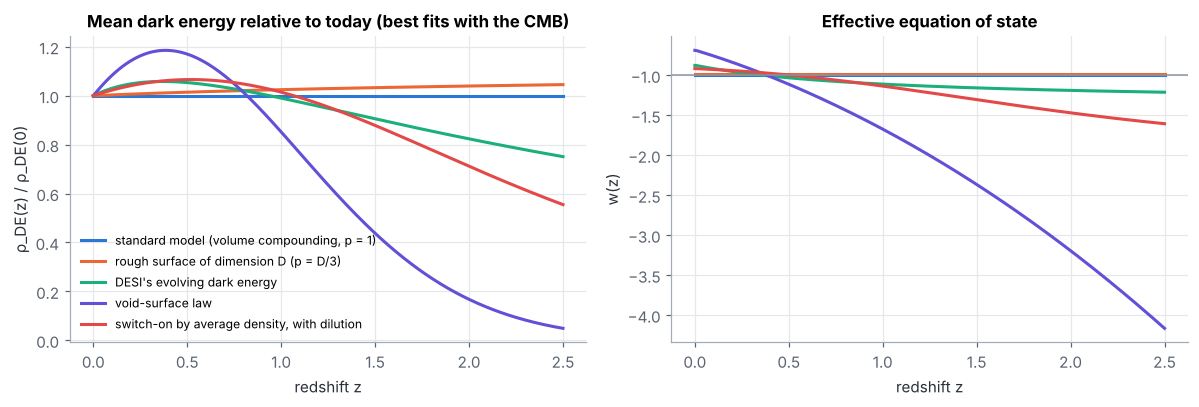

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
zz = np.linspace(0, 2.5, 250)
show = ["standard model (volume compounding, p = 1)", "rough surface of dimension D (p = D/3)", "DESI's evolving dark energy",
        "void-surface law", "switch-on by average density, with dilution"]
for name, c in zip(show, LAW_COLOURS):
    h = fits_cmb[name]["hist"]
    axs[0].plot(zz, h.f(zz), color=c, label=name)
    axs[1].plot(zz, h.w_eff(zz), color=c, label=name)
axs[0].set(title="Mean dark energy relative to today (best fits with the CMB)", xlabel="redshift z", ylabel="ρ_DE(z) / ρ_DE(0)")
axs[1].set(title="Effective equation of state", xlabel="redshift z", ylabel="w(z)")
axs[1].axhline(-1, color=COL["muted"], lw=1); axs[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT / "surface_histories.png", bbox_inches="tight"); plt.show()

## 15. Write your own history

A history only needs $f(z)$, the mean dark energy relative to today. Write it as a function of the redshift grid `ZH` and its parameters, wrap it in `History`, and hand it to `fit_family`. The example ties dark energy to the share of the universe's volume that is emptier than `x_void` times the mean (the void fraction from section 3), raised to a power `beta`, with dilution `p`.

In [20]:
def void_fraction_history(x_void, beta, p):
    s = np.sqrt(np.log1p((sigma_tophat(2.0) * _D_WEB) ** 2))
    fv = special.ndtr((math.log(x_void) + s ** 2 / 2) / s)          # volume share below x_void × mean
    f = (fv / fv[0]) ** beta * (1 + _ZD) ** (6 * (1 - p))
    z = np.concatenate([_ZD, np.geomspace(_ZD[-1] * 1.01, 1e8, 30)])
    return History(z, np.concatenate([f, np.full(30, f[-1])]), name="void fraction")

mine = fit_family(lambda lx, beta, p: void_fraction_history(10 ** lx, beta, p),
                  starts=[[0.31, -0.5, 0.5, 0.95], [0.31, -1.0, 1.0, 0.9]],
                  bounds=[(-3.0, -0.05), (0.0, 6.0), (0.6, 1.3)])
print(f"Δχ² vs the standard model with the CMB: {mine['chi2'] - fits_cmb['standard model (volume compounding, p = 1)']['chi2']:+.2f} "
      f"(3 extra numbers); x_void = {10 ** mine['params'][0]:.3g}, beta = {mine['params'][1]:.2f}, p = {mine['params'][2]:.3f}")

Δχ² vs the standard model with the CMB: -6.00 (3 extra numbers); x_void = 0.249, beta = 0.59, p = 0.907


## 16. Limits of this lab, and good next tests

**Approximations**

* **A simple cosmic web.** It is lognormal in 2 Mpc cells with linear-theory width. Real galaxies and clusters are far denser than the cells, but they fill so little volume that the mean dark energy hardly notices.
* **Linear growth and a single velocity slope.** The 2M++ predictions were made with standard gravity, so the slope test is a ratio test, not a full reanalysis.
* **Energy bookkeeping.** Dark energy that changes from place to place and over time needs something to exchange energy with. The lab treats the law as a phenomenological description and does not model that exchange.
* **A compressed CMB.** Three numbers stand in for Planck's full likelihood, with a one-off calibration of the decoupling redshift. This is reliable for late-time dark energy; models that change the early universe need the full likelihood.
* **Free BAO and supernova scales.** Leaving $H_0 r_d$ and the supernova scale free keeps the Hubble tension out of the comparison, at the cost of some constraining power that DESI's own analysis uses.

**Good next tests**

* **Growth-rate measurements** ($f\sigma_8$ from redshift-space distortions at $z = 0$–$1.5$) to extend section 5 beyond the local universe.
* **Void catalogues** (SDSS, DESI DR1), to compare void galaxies with wall galaxies of the same mass. That is the most direct test of whether voids push.
* **The reserved galaxies** in your galaxy run, once a law is frozen.